# Предсказание заболеваний сердца
## Описание датасета

1. age — возраст
2. sex — пол
3. chest pain type — тип боли в груди (4 значения)
4. resting blood pressure — артериальное давление в покое
5. serum cholestoral in mg/dl — холестерин сыворотки крови, мг/дл
6. fasting blood sugar > 120 mg/dl — уровень сахара в крови натощак > 120 мг/дл
7. resting electrocardiographic results — результаты электрокардиографии в покое (значения 0, 1, 2)
8. maximum heart rate achieved — максимальная достигнутая частота сердечных сокращений
9. exercise induced angina — стенокардия, вызванная физической нагрузкой
10. oldpeak — депрессия сегмента ST, вызванная нагрузкой, относительно состояния покоя
11. the slope of the peak exercise ST segment — наклон сегмента ST на пике нагрузки
12. number of major vessels (0-3) colored by flourosopy — число крупных сосудов (0–3), окрашенных при флюороскопии
13. thal — талассемия: 0 = норма; 1 = фиксированный дефект; 2 = обратимый дефект
14. target — целевая переменная: 0 = здоров, 1 = есть заболевание

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Датасет


In [2]:
class HeartDataset(Dataset):
    def __init__(self, csv_path, target_col="target"):
        df = pd.read_csv(csv_path)
        self.X = torch.tensor(df.drop(columns=[target_col]).values, dtype=torch.float32)
        self.y = torch.tensor(df[target_col].values, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class HeartDatasetPreprocessed(HeartDataset):
    NUMERIC = ["age", "trestbps", "chol", "thalach", "ca", "oldpeak"]
    CATEGORICAL = ["cp", "restecg", "slope",  "thal"]  # бинарные sex, fbs, exang уже 0/1

    def __init__(self, csv_path, target_col="target"):
        df = pd.read_csv(csv_path)
        y = df[target_col]
        X = df.drop(columns=[target_col])

        X[self.NUMERIC] = (X[self.NUMERIC] - X[self.NUMERIC].mean()) / X[self.NUMERIC].std()
        X = pd.get_dummies(X, columns=self.CATEGORICAL, dtype=float)

        self.feature_names = list(X.columns)
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32).unsqueeze(1)


dataset = HeartDataset("heart.csv")
print("Объектов:", len(dataset), "| признаков:", dataset.X.shape[1])

train_size = int(0.8 * len(dataset))
train_set, test_set = random_split(
    dataset, [train_size, len(dataset) - train_size],
    generator=torch.Generator().manual_seed(SEED),
)

BATCH_SIZE = 32
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

Объектов: 1025 | признаков: 13


## Модель

In [3]:
class HeartNet(nn.Module):
    def __init__(self, in_features, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),  # логит; сигмоида внутри BCEWithLogitsLoss
        )

    def forward(self, x):
        return self.net(x)

In [4]:
# создаем объекты модели, функции потерь и оптимизатора
model = HeartNet(in_features=dataset.X.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses = []
test_losses  = []

## Обучаем модель

In [5]:
n_epochs = 100

for epoch in range(n_epochs):
    model.train()
    train_losses_per_epoch = []
    test_losses_per_epoch  = []
    for data, target in train_loader:
        optimizer.zero_grad()
        output = model(data.to(device))
        loss = criterion(output, target.to(device))
        loss.backward()
        optimizer.step()
        train_losses_per_epoch.append(loss.item())

    train_losses.append(np.mean(train_losses_per_epoch))
    model.eval()
    with torch.no_grad():
        for data, target in test_loader:
            output = model(data.to(device))
            loss = criterion(output, target.to(device))
            test_losses_per_epoch.append(loss.item())
        test_losses.append(np.mean(test_losses_per_epoch))

    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1:3d} | train loss {train_losses[-1]:.4f} | test loss {test_losses[-1]:.4f}")

epoch  10 | train loss 0.5466 | test loss 0.5836
epoch  20 | train loss 0.4793 | test loss 0.5287
epoch  30 | train loss 0.4001 | test loss 0.4646
epoch  40 | train loss 0.3616 | test loss 0.4438
epoch  50 | train loss 0.3359 | test loss 0.4505
epoch  60 | train loss 0.3263 | test loss 0.4506
epoch  70 | train loss 0.3372 | test loss 0.4469
epoch  80 | train loss 0.3167 | test loss 0.4763
epoch  90 | train loss 0.3111 | test loss 0.4675
epoch 100 | train loss 0.3187 | test loss 0.4453


## Оцениваем качество обученной модели

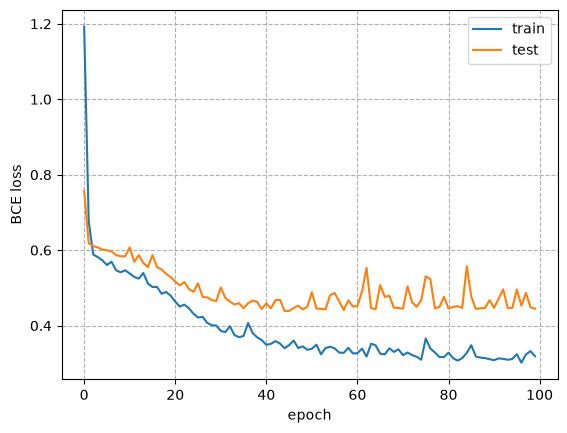

In [6]:
plt.plot(train_losses, label='train')
plt.plot(test_losses, label='test')
plt.xlabel('epoch')
plt.ylabel('BCE loss')
plt.grid(True, linestyle='--')
plt.legend()

In [7]:
from sklearn.metrics import f1_score

def test(model, loader):
    """Возвращает F1-меру модели на данных из loader."""
    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for data, target in loader:
            output = model(data.to(device))
            y_pred.extend((output > 0).int().flatten().tolist())  # логит > 0 <=> вероятность > 0.5
            y_true.extend(target.int().flatten().tolist())
    return f1_score(y_true, y_pred)

print(f"F1: {test(model, test_loader)}")

F1: 0.8095238095238095


## Лабораторная работа 5
1. Используя датасет ```HeartDatasetPreprocessed``` подобрать оптимальные значения гиперпараметров (hidden, lr, batch_size, n_epochs, число слоёв) для оптимального значения f1 и записать что на что меняли. Описать как проводили экспирименты по подбору.
2. Построить матрицу ошибок. Рассчитать precision и recall.
3. *Выдвинуть гипотезу о причине утечки данных в тест и устранить ее. Подтвердить или опровергнуть выдвинутую гипотезу экспириментально.

## Пример отчета по первому пункту лабораторной 5
hidden | lr | batch_size | n_epochs | число слоёв | f1
|---|---|---|---|---|---|
|123|0.123|123|123|12|0.85|
...